# Часть 1. Проверка гипотезы в Python и составление аналитической записки

Вы предобработали данные в SQL, и теперь они готовы для проверки гипотезы в Python. Загрузите данные пользователей из Москвы и Санкт-Петербурга c суммой часов их активности из файла yandex_knigi_data.csv. Если работаете локально, скачать файл можно по ссылке.

Проверьте наличие дубликатов в идентификаторах пользователей. Сравните размеры групп, их статистики и распределение.

Напомним, как выглядит гипотеза: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

По результатам анализа данных подготовьте аналитическую записку, в которой опишите:

Выбранный тип t-теста и уровень статистической значимости.

Результат теста, или p-value.

Вывод на основе полученного p-value, то есть интерпретацию результатов.

Одну или две возможные причины, объясняющие полученные результаты.

## Напишите заголовок первой части проекта здесь

- Автор: Аргунова Ева
- Дата: 30.08.2026

## Цели и задачи проекта

**Цель проекта** — проверить гипотезу о том, что пользователи из Санкт-Петербурга в среднем проводят больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы, а также оценить результаты A/B-теста нового интерфейса интернет-магазина.

**Основные задачи:**

1. Подготовить и проанализировать данные пользователей Яндекс Книг.
2. Сравнить активность пользователей из Москвы и Санкт-Петербурга и статистически проверить гипотезу.
3. Сформулировать выводы по результатам проверки гипотезы.
4. Загрузить и подготовить данные A/B-теста интернет-магазина.
5. Проверить корректность проведения A/B-теста.
6. Рассчитать конверсию зарегистрированных пользователей в покупателей за семь дней после регистрации.
7. Оценить статистическую значимость различий между группами A и B.
8. Сформулировать итоговые выводы по результатам A/B-теста.

## Описание данных

### Данные Яндекс Книг

Для проверки гипотезы используются данные пользователей из Москвы и Санкт-Петербурга с суммой часов их активности.

- `city` — город пользователя;
- `puid` — идентификатор пользователя;
- `hours` — общее количество часов чтения и прослушивания книг в приложении.

### Данные A/B-теста

Для анализа эксперимента используются две таблицы.

**Таблица участников теста `ab_test_participants.csv`:**

- `user_id` — идентификатор пользователя;
- `group` — группа пользователя;
- `ab_test` — название A/B-теста;
- `device` — устройство, с которого происходила регистрация.

**Таблица событий `ab_test_events`:**

- `user_id` — идентификатор пользователя;
- `event_dt` — дата и время события;
- `event_name` — тип события;
- `details` — дополнительные данные о событии.

В рамках A/B-теста анализируется тест `interface_eu_test`, в котором группа A является контрольной, а группа B использует новый интерфейс.

## Содержимое проекта

1. **Проверка гипотезы в Python**
   - загрузка и подготовка данных;
   - проверка дубликатов и размеров групп;
   - анализ статистик активности пользователей;
   - проверка гипотезы с помощью статистического теста;
   - подготовка аналитической записки.

2. **Анализ результатов A/B-теста**
   - загрузка и подготовка данных;
   - проверка корректности распределения пользователей по группам;
   - проверка пересечений и распределения по устройствам;
   - расчёт конверсии в покупку за семь дней после регистрации;
   - статистическая проверка различий между группами;
   - итоговый вывод по результатам эксперимента.

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [1]:
# Импортируем библиотеки
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest

In [2]:
knigi = pd.read_csv('/datasets/yandex_knigi_data.csv')

knigi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8784 non-null   int64  
 1   city        8784 non-null   object 
 2   puid        8784 non-null   int64  
 3   hours       8784 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 274.6+ KB


In [3]:
knigi.head()

,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434


### Проверка дубликатов

In [4]:
knigi['puid'].duplicated().sum()

244

Получено **244 повторных вхождения идентификаторов пользователей**. Это означает, что некоторые пользователи представлены в данных более одного раза.

Удалять эти записи сразу не будем, так как повторение `puid` не обязательно означает ошибку в данных. Проверим, как именно распределены такие пользователи по городам, чтобы понять причину повторений.

In [5]:
# Проверяем, сколько уникальных пользователей и строк в данных
print(f'Количество строк: {len(knigi)}')
print(f'Количество уникальных пользователей: {knigi["puid"].nunique()}')

Количество строк: 8784
Количество уникальных пользователей: 8540


In [6]:
# Выводим все строки пользователей, которые встречаются в данных более одного раза
duplicated_users = knigi[knigi['puid'].duplicated(keep=False)].sort_values('puid')

duplicated_users.head(20)

,Unnamed: 0,city,puid,hours
35,35,Москва,2637041,10.317371
6247,6247,Санкт-Петербург,2637041,3.883926
134,134,Москва,9979490,32.415573
6274,6274,Санкт-Петербург,9979490,1.302997
145,145,Москва,10597984,42.931506
6279,6279,Санкт-Петербург,10597984,9.041320
150,150,Москва,10815097,9.086655
6283,6283,Санкт-Петербург,10815097,0.323291
187,187,Москва,13626259,21.104167
6300,6300,Санкт-Петербург,13626259,1.648434


По примерам видно, что повторяющиеся `puid` соответствуют разным городам: один и тот же пользователь встречается как в Москве, так и в Санкт-Петербурге.
Следовательно, повторные записи не являются полными дубликатами и содержат разную информацию об активности пользователя в разных городах. Удалять их не будем, поскольку это приведёт к потере части данных.

Чтобы наш вывод был не только по первым 20 строкам, а подтверждался для всех 244 повторных записей, проверим, **действительно ли повторяющиеся пользователи связаны с разными городами.**

In [7]:
# Проверяем количество уникальных городов для каждого пользователя
duplicated_city_count = (duplicated_users.groupby('puid')['city'].nunique())

print('Пользователей с повторяющимся puid:', duplicated_city_count.size)

print('Пользователей, встречающихся в нескольких городах:', (duplicated_city_count > 1).sum())

Пользователей с повторяющимся puid: 244
Пользователей, встречающихся в нескольких городах: 244


In [8]:
# Проверяем количество полностью идентичных строк
full_duplicates = knigi.duplicated().sum()

print(f'Количество полностью дублирующихся строк: {full_duplicates}')

Количество полностью дублирующихся строк: 0


In [9]:
# Удаляем пользователей, представленных одновременно в двух городах
duplicated_puids = duplicated_city_count[duplicated_city_count > 1].index

knigi_clean = knigi[~knigi['puid'].isin(duplicated_puids)].copy()

print(f'Количество строк после удаления: {len(knigi_clean)}')
print(f'Количество уникальных пользователей после удаления: {knigi_clean["puid"].nunique()}')

Количество строк после удаления: 8296
Количество уникальных пользователей после удаления: 8296


#### Промежуточный вывод
В данных обнаружено **244 пользователя с повторяющимся `puid`**. Проверка показала, что все 244 пользователя представлены одновременно в Москве и Санкт-Петербурге, при этом значения их активности различаются. Полных дубликатов строк не обнаружено.

Поскольку один и тот же пользователь не должен одновременно учитываться в двух сравниваемых группах, такие записи могут нарушить независимость выборок. Поэтому исключаем **244 пользователей вместе с обеими их записями** из дальнейшего анализа.

После очистки в данных остаётся **8 296 уникальных пользователей**, по одному наблюдению на пользователя.


### Сравнение размеров групп

In [10]:
# Считаем количество пользователей в каждом городе
group_sizes = knigi_clean.groupby('city')['puid'].nunique()

print('Количество уникальных пользователей по городам:')
print(group_sizes)

Количество уникальных пользователей по городам:
city
Москва             5990
Санкт-Петербург    2306
Name: puid, dtype: int64


#### Результат

В данных представлено 5 990 уникальных пользователя из Москвы и 2 306 уникальных пользователей из Санкт-Петербурга. Размеры групп заметно различаются: московская группа примерно в 2,4 раза больше петербургской.

При этом различие в размерах выборок само по себе не препятствует проведению статистического теста. Поэтому далее сравним основные статистические характеристики и распределение времени активности пользователей в обеих группах.


### Статистики активности

In [11]:
# Рассчитываем основные статистики активности пользователей по городам
group_stats = knigi_clean.groupby('city')['hours'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max'])

group_stats

,count,mean,median,std,min,max
city,,,,,,
Москва,5990,10.848192,0.888232,36.925622,0.000022,857.209373
Санкт-Петербург,2306,11.264433,0.875355,39.831755,0.000025,978.764775


#### Результат

Средняя активность пользователей в Санкт-Петербурге составляет **11,26 часа**, что выше показателя Москвы — **10,85 часа**. При этом медианное значение в Санкт-Петербурге немного ниже: **0,88 часа против 0,89 часа** в Москве.

В обеих группах стандартное отклонение значительно превышает среднее значение, а максимальная активность существенно выше медианы. Это указывает на выраженную правостороннюю асимметрию распределения и наличие пользователей с очень высокой активностью.

Таким образом, по среднему значению активность пользователей Санкт-Петербурга выглядит немного выше, однако медианные значения практически одинаковы. Для определения статистической значимости различия необходимо дополнительно изучить распределение данных и провести односторонний t-тест.


### Распределение

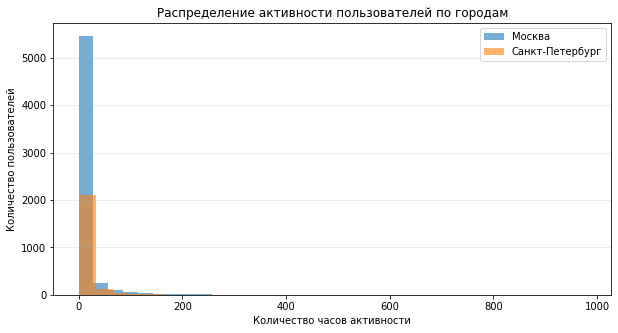

In [12]:
# Сравниваем распределение активности пользователей в двух городах
plt.figure(figsize=(10, 5))

plt.hist(
    knigi_clean[knigi_clean['city'] == 'Москва']['hours'],
    bins=30,
    alpha=0.6,
    label='Москва'
)

plt.hist(
    knigi_clean[knigi_clean['city'] == 'Санкт-Петербург']['hours'],
    bins=30,
    alpha=0.6,
    label='Санкт-Петербург'
)

plt.title('Распределение активности пользователей по городам')
plt.xlabel('Количество часов активности')
plt.ylabel('Количество пользователей')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

### Выбор статистического критерия

Для сравнения средней активности пользователей Москвы и Санкт-Петербурга используем **односторонний t-тест Welch для независимых выборок**.

Так как сравниваются две независимые группы, а их дисперсии могут различаться, выбираем критерий Welch, который не предполагает равенства дисперсий. Односторонний тест соответствует альтернативной гипотезе о том, что средняя активность пользователей в Санкт-Петербурге **выше**, чем в Москве.

In [13]:
# Выделяем независимые выборки активности пользователей по городам
moscow = knigi_clean.loc[knigi_clean['city'] == 'Москва', 'hours']
spb = knigi_clean.loc[knigi_clean['city'] == 'Санкт-Петербург', 'hours']

print(f'Размер выборки Москвы: {len(moscow)}')
print(f'Размер выборки Санкт-Петербурга: {len(spb)}')

Размер выборки Москвы: 5990
Размер выборки Санкт-Петербурга: 2306


In [14]:
# Уровень статистической значимости
alpha = 0.05

# Односторонний t-тест Уэлча для сравнения средних двух независимых выборок
stat_welch_ttest, p_value_welch_ttest = stats.ttest_ind(
    spb,
    moscow,
    equal_var=False,
    alternative='greater'
)

print(f'p-value теста Уэлча = {p_value_welch_ttest:.4f}')

if p_value_welch_ttest <= alpha:
    print('Отвергаем нулевую гипотезу H₀.')
else:
    print('Нет оснований отвергнуть нулевую гипотезу H₀.')

p-value теста Уэлча = 0.3318
Нет оснований отвергнуть нулевую гипотезу H₀.


#### Результат

В результате одностороннего t-теста Уэлча получили **p-value = 0,3318**. Уровень статистической значимости составляет **α = 0,05**. Поскольку **p-value > α**, у нас нет оснований отвергнуть нулевую гипотезу H₀.

Таким образом, статистически значимых оснований утверждать, что средняя активность пользователей в Санкт-Петербурге выше, чем в Москве, **не обнаружено**. Несмотря на то, что по описательной статистике средняя активность в Санкт-Петербурге немного выше (**11,26 часа против 10,85 часа**), полученная разница не является статистически значимой.

## 3. Аналитическая записка
По результатам анализа данных подготовьте аналитическую записку, в которой опишете:

- Выбранный тип t-теста и уровень статистической значимости.

- Результат теста, или p-value.

- Вывод на основе полученного p-value, то есть интерпретацию результатов.

- Одну или две возможные причины, объясняющие полученные результаты.



Для проверки гипотезы о том, что пользователи из Санкт-Петербурга в среднем проводят больше времени за чтением и прослушиванием книг, чем пользователи из Москвы, был выбран **односторонний t-тест Уэлча для двух независимых выборок**. Такой критерий позволяет сравнить средние значения двух групп без предположения о равенстве их дисперсий. Уровень статистической значимости принят равным **α = 0,05**.

По результатам теста получили **p-value = 0,3318**. Поскольку полученное значение превышает установленный уровень значимости (**0,3318 > 0,05**), **нет оснований отвергнуть нулевую гипотезу H₀**.

Таким образом, несмотря на то, что средняя активность пользователей в Санкт-Петербурге выше, чем в Москве (**11,26 часа против 10,85 часа**), статистически значимых оснований утверждать, что пользователи из Санкт-Петербурга проводят в приложении больше времени, не обнаружено.

Полученный результат может объясняться тем, что **наблюдаемая разница средних относительно невелика по сравнению с разбросом активности пользователей**. Кроме того, распределение активности имеет выраженную правостороннюю асимметрию: небольшая часть пользователей проводит в приложении значительно больше времени, что увеличивает разброс данных и затрудняет выявление небольшого различия между группами как статистически значимого. Также возможной причиной может быть **схожий образ жизни и бытовые привычки жителей Москвы и Санкт-Петербурга**, что способствует близким показателям использования сервиса.

----

# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.



**Цель исследования** — оценить результаты A/B-теста нового интерфейса интернет-магазина BitMotion Kit и определить, привёл ли новый интерфейс к увеличению конверсии пользователей в покупку.

## 2. Загрузите данные, оцените их целостность.


In [15]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [16]:
# Проверяем структуру и типы данных таблиц
participants.info()
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


In [17]:
display(participants.head(), events.head())

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


In [18]:
# Проверяем наличие пропущенных значений
print('Пропуски в participants:')
print(participants.isna().sum())

print('\nПропуски в events:')
print(events.isna().sum())

Пропуски в participants:
user_id    0
group      0
ab_test    0
device     0
dtype: int64

Пропуски в events:
user_id            0
event_dt           0
event_name         0
details       538264
dtype: int64


In [19]:
# Проверяем наличие полностью дублирующихся строк
print(f'Полные дубликаты в participants: {participants.duplicated().sum()}')
print(f'Полные дубликаты в events: {events.duplicated().sum()}')

Полные дубликаты в participants: 0
Полные дубликаты в events: 36318


In [20]:
# Проверяем период, за который представлены пользовательские события
print(f'Минимальная дата события: {events["event_dt"].min()}')
print(f'Максимальная дата события: {events["event_dt"].max()}')

Минимальная дата события: 2020-12-01 00:00:00
Максимальная дата события: 2020-12-31 23:59:48


In [21]:
# Уникальность идентификаторов
print(f'Повторяющиеся user_id: {participants["user_id"].duplicated().sum()}')

Повторяющиеся user_id: 887


In [22]:
# Анализируем полные дубликаты событий
duplicated_events = events[events.duplicated(keep=False)]

print(f'Количество строк в полных дубликатах: {len(duplicated_events)}')
print(f'Количество пользователей: {duplicated_events["user_id"].nunique()}')
print(f'Количество типов событий: {duplicated_events["event_name"].nunique()}')

Количество строк в полных дубликатах: 69956
Количество пользователей: 24511
Количество типов событий: 4


In [23]:
# Проверяем распределение полных дубликатов по типам событий
duplicated_events['event_name'].value_counts()

login           38253
product_page    15799
purchase         8077
product_cart     7827
Name: event_name, dtype: int64

#### Результат

В ходе проверки структуры данных установлено, что таблица `participants` содержит **14 525 записей**, а таблица `events` — **787 286 событий**. Пропущенные значения в таблице участников отсутствуют. В таблице событий пропуски обнаружены только в поле `details`, которое содержит дополнительную информацию о событиях.

Полных дубликатов в таблице `participants` не обнаружено. В таблице `events` выявлено **36 318 повторных записей**. При дополнительной проверке установлено, что повторяющиеся события относятся к разным пользователям и всем четырём типам событий. Поэтому на данном этапе удалять их не будем, так как одинаковые события не обязательно свидетельствуют об ошибке в данных.

В таблице `participants` обнаружено **887 повторяющихся идентификаторов пользователей**. Это не рассматривается как ошибка на данном этапе, поскольку один пользователь может участвовать в разных тестах. 
Данные о событиях представлены за период с **1 по 31 декабря 2020 года**. 

## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделите пользователей, участвующих в тесте, и проверьте:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [24]:
# Проверяем состав тестов и количество участников в каждом из них
participants.groupby('ab_test')['user_id'].nunique()

ab_test
interface_eu_test          10850
recommender_system_test     3675
Name: user_id, dtype: int64

In [25]:
# Проверяем распределение уникальных пользователей по тестам и группам
participants.groupby(['ab_test', 'group'])['user_id'].nunique()

ab_test                  group
interface_eu_test        A        5383
                         B        5467
recommender_system_test  A        2747
                         B         928
Name: user_id, dtype: int64

In [26]:
# Выделяем участников теста interface_eu_test
participants_eu = participants[participants['ab_test'] == 'interface_eu_test'].copy()

In [27]:
# Проверяем количество уникальных участников теста по группам
participants_eu.groupby('group')['user_id'].nunique()

group
A    5383
B    5467
Name: user_id, dtype: int64

In [28]:
# Проверяем пересечение пользователей основного и конкурирующего тестов
interface_users = set(
    participants[participants['ab_test'] == 'interface_eu_test']['user_id'])

recommender_users = set(
    participants[participants['ab_test'] == 'recommender_system_test']['user_id'])

intersection = interface_users & recommender_users

print(f'Участников interface_eu_test: {len(interface_users)}')
print(f'Участников recommender_system_test: {len(recommender_users)}')
print(f'Пересечение пользователей: {len(intersection)}')

Участников interface_eu_test: 10850
Участников recommender_system_test: 3675
Пересечение пользователей: 887


In [29]:
# Исключаем пользователей, одновременно участвующих в основном и конкурирующем тестах
overlap_users = participants.groupby('user_id')['ab_test'].nunique()
overlap_users = overlap_users[overlap_users > 1].index

participants_clean = participants[
    ~participants['user_id'].isin(overlap_users)].copy()

In [30]:
# Выделяем участников основного теста после удаления пересечений
participants_eu = participants_clean[
    participants_clean['ab_test'] == 'interface_eu_test'].copy()

participants_eu.groupby('group')['user_id'].nunique()

group
A    4952
B    5011
Name: user_id, dtype: int64

###   Результат

Для анализа был выделен тест `interface_eu_test`. Изначально в нём участвовали 10 850 уникальных пользователей. В результате проверки было обнаружено 887 пользователей, которые одновременно участвовали в основном и конкурирующем тесте `recommender_system_test`. Такие пользователи были исключены из дальнейшего анализа.

После удаления пересечений в основном тесте осталось **9 963 уникальных пользователя**: **4 952 пользователя в группе A** и **5 011 пользователей в группе B**. Разница между группами составляет 59 пользователей, поэтому распределение участников можно считать достаточно равномерным.

Таким образом, после очистки выборка основного теста не содержит пользователей, одновременно участвующих в конкурирующем эксперименте, что позволяет использовать её для дальнейшего анализа результатов A/B-теста.

3\.2 Проанализируйте данные о пользовательской активности по таблице `ab_test_events`:

- оставьте только события, связанные с участвующими в изучаемом тесте пользователями;

In [31]:
# Оставляем только события пользователей, участвующих в основном тесте
events_eu = events[events['user_id'].isin(participants_eu['user_id'])].copy()

print(f'Количество событий участников interface_eu_test: {len(events_eu)}')
print(f'Количество уникальных пользователей: {events_eu["user_id"].nunique()}')

Количество событий участников interface_eu_test: 73815
Количество уникальных пользователей: 9963


- определите горизонт анализа: рассчитайте время (лайфтайм) совершения события пользователем после регистрации и оставьте только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [32]:
# Проверяем, какие события представлены в данных
events_eu['event_name'].value_counts()

login           27360
product_page    17614
registration     9963
purchase         9487
product_cart     9391
Name: event_name, dtype: int64

In [33]:
# Определяем время регистрации каждого пользователя
registration_dt = (
    events_eu[events_eu['event_name'] == 'registration']
    .groupby('user_id')['event_dt']
    .min()
    .rename('registration_dt')
)

registration_dt.head()

user_id
0002CE61FF2C4011   2020-12-07 04:37:31
001E72F50D1C48FA   2020-12-17 15:44:05
002412F1EB3F6E38   2020-12-09 09:36:50
002540BE89C930FB   2020-12-08 18:06:07
0031F1B5E9FBF708   2020-12-14 00:47:10
Name: registration_dt, dtype: datetime64[ns]

In [34]:
# Добавляем время регистрации пользователя к его событиям
events_eu = events_eu.merge(
    registration_dt,
    on='user_id',
    how='left')

# Рассчитываем время от регистрации до каждого события
events_eu['lifetime'] = events_eu['event_dt'] - events_eu['registration_dt']

# Оставляем события, произошедшие в течение первых семи дней после регистрации
events_eu_7d = events_eu[
    (events_eu['lifetime'] >= pd.Timedelta(0)) &
    (events_eu['lifetime'] <= pd.Timedelta(days=7))
].copy()

print(f'Событий в первые 7 дней: {len(events_eu_7d)}')
print(f'Уникальных пользователей: {events_eu_7d["user_id"].nunique()}')

Событий в первые 7 дней: 63805
Уникальных пользователей: 9963


Оцените достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [35]:
# Параметры теста
baseline_conversion = 0.30
target_conversion = 0.33
alpha = 0.05
power = 0.80

# Рассчитываем размер эффекта
effect_size = proportion_effectsize(
    baseline_conversion,
    target_conversion
)

# Рассчитываем необходимый размер выборки на одну группу
sample_size = NormalIndPower().solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1,
    alternative='two-sided'
)

sample_size = int(np.ceil(sample_size))

print(f'Необходимый размер выборки на одну группу: {sample_size}')
print(f'Необходимый общий размер выборки: {sample_size * 2}')

# Сравниваем с фактическим размером групп
actual_group_sizes = participants_eu.groupby('group')['user_id'].nunique()

print('\nФактический размер групп:')
print(actual_group_sizes)

print(f'\nМинимальный необходимый размер группы: {sample_size}')

for group, size in actual_group_sizes.items():
    if size >= sample_size:
        print(f'Группа {group}: размер выборки достаточен.')
    else:
        print(f'Группа {group}: размер выборки недостаточен.')

Необходимый размер выборки на одну группу: 3762
Необходимый общий размер выборки: 7524

Фактический размер групп:
group
A    4952
B    5011
Name: user_id, dtype: int64

Минимальный необходимый размер группы: 3762
Группа A: размер выборки достаточен.
Группа B: размер выборки достаточен.


### Результат
Расчёт показал, что для обнаружения ожидаемого эффекта необходимо не менее **3 762 пользователей в каждой группе**, или **7 524 пользователей суммарно**.

Фактически в тесте участвуют **4 952 пользователя в группе A** и **5 011 пользователей в группе B**. Обе группы превышают рассчитанный минимальный размер выборки.

Таким образом, **размер выборки достаточен для проведения A/B-теста** с заданными параметрами. Тест обладает достаточной мощностью для выявления изменения конверсии на **3 процентных пункта**.

- рассчитайте для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [36]:
# Количество пользователей, совершивших покупку в первые 7 дней
purchases = (
    events_eu_7d[events_eu_7d['event_name'] == 'purchase']
    .groupby('user_id')
    .size()
    .reset_index(name='purchase_count')
)

# Добавляем информацию о группе пользователя
purchases = purchases.merge(
    participants_eu[['user_id', 'group']],
    on='user_id',
    how='left'
)

# Количество уникальных покупателей по группам
buyers_by_group = purchases.groupby('group')['user_id'].nunique()

# Общее количество участников по группам
users_by_group = participants_eu.groupby('group')['user_id'].nunique()

# Объединяем результаты в одну таблицу
conversion_data = pd.DataFrame({
    'visitors': users_by_group,
    'buyers': buyers_by_group
})

# Рассчитываем конверсию
conversion_data['conversion'] = (
    conversion_data['buyers'] / conversion_data['visitors'] * 100
)

conversion_data

,visitors,buyers,conversion
group,,,
A,4952,1377,27.806947
B,5011,1480,29.535023


- сделайте предварительный общий вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной.

#### Результат

В контрольной группе A покупку в течение первых семи дней совершили **1 377 пользователей из 4 952**, что соответствует конверсии **27,81%**.

В тестовой группе B покупку совершили **1 480 пользователей из 5 011**, конверсия составила **29,54%**.

Таким образом, конверсия в тестовой группе увеличилась по сравнению с контрольной на **1,73 процентного пункта** (с 27,81% до 29,54%). 

На предварительном уровне можно отметить **положительную динамику пользовательской активности в тестовой группе**: пользователи с новым интерфейсом несколько чаще совершали покупки в течение первых семи дней после регистрации.

При этом заявленный в техническом задании эффект составляет **не менее 3 процентных пунктов**. Фактическое увеличение конверсии пока составляет только **1,73 процентного пункта**, поэтому ожидаемый эффект на данном этапе не достигнут.

## 4. Проведите оценку результатов A/B-тестирования:

- Проверьте изменение конверсии подходящим статистическим тестом, учитывая все этапы проверки гипотез.

Для проверки статистической значимости изменения конверсии сформулируем следующие гипотезы:

- **H₀:** конверсия в тестовой группе B не выше конверсии в контрольной группе A.
- **H₁:** конверсия в тестовой группе B выше конверсии в контрольной группе A.

Уровень статистической значимости: **α = 0,05**.

In [37]:
# Данные контрольной группы A
buyers_a = conversion_data.loc['A', 'buyers']
visitors_a = conversion_data.loc['A', 'visitors']

# Данные тестовой группы B
buyers_b = conversion_data.loc['B', 'buyers']
visitors_b = conversion_data.loc['B', 'visitors']

# Уровень статистической значимости
alpha = 0.05

# Проверяем гипотезу B > A
z_stat, p_value = proportions_ztest(
    count=[buyers_b, buyers_a],
    nobs=[visitors_b, visitors_a],
    alternative='larger'
)

print(f'z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.4f}')

if p_value < alpha:
    print('Отвергаем нулевую гипотезу H₀.')
else:
    print('Нет оснований отвергнуть нулевую гипотезу H₀.')

z-статистика: 1.9070
p-value: 0.0283
Отвергаем нулевую гипотезу H₀.


- Опишите выводы по проведённой оценке результатов A/B-тестирования. Что можно сказать про результаты A/B-тестирования? Был ли достигнут ожидаемый эффект в изменении конверсии?

## Выводы по результатам A/B-тестирования

Для проверки изменения конверсии был выбран **односторонний z-тест для сравнения двух пропорций**. Такой тест подходит для A/B-тестирования, поскольку конверсия является долей пользователей, совершивших покупку, а нам необходимо сравнить две независимые доли — конверсию в контрольной группе A и тестовой группе B.

Односторонний тест выбран потому, что согласно техническому заданию нас интересует именно **увеличение конверсии** после внедрения нового интерфейса.

Перед проведением теста была проверена достаточность выборки. Расчёт показал, что для обнаружения ожидаемого эффекта при базовой конверсии 30%, мощности 80% и уровне значимости 5% необходимо не менее **3 762 пользователей в каждой группе**. Фактический размер групп превышает это значение, поэтому выборка достаточна для проведения теста.

По результатам расчёта конверсия в контрольной группе A составила **27,81%**, а в тестовой группе B — **29,54%**. Таким образом, конверсия в тестовой группе увеличилась на **1,73 процентного пункта**.

Статистический тест дал следующие результаты:

- **z-статистика = 1,9070**;
- **p-value = 0,0283**.

Так как **p-value < α (0,0283 < 0,05)**, нулевая гипотеза отвергается. Это означает, что полученных данных достаточно, чтобы считать увеличение конверсии в тестовой группе **статистически значимым**. Иными словами, вероятность получить такое или ещё более выраженное различие между группами случайно при справедливости нулевой гипотезы составляет около **2,83%**.

При этом ожидаемый бизнес-эффект, указанный в техническом задании, **не был достигнут**. Требовалось увеличение конверсии минимум на **3 процентных пункта**, тогда как фактическое увеличение составило только **1,73 процентного пункта**.

Таким образом, **новый интерфейс статистически значимо увеличил конверсию, однако необходимый по техническому заданию эффект в +3 процентных пункта достигнут не был**. Поэтому по результатам данного A/B-теста нельзя считать, что новая версия интерфейса полностью соответствует поставленной цели.